# Notebook 1 — Data Exploration (Intel Berkeley Lab sensors)

**Goal:** find out exactly what is in `data.txt` before changing anything.

**Input:** `data/raw/data.txt`  
**Outputs:** tables in `outputs/notebook01/`, figures in `figures/notebook01/`

**Rules for this notebook:** the raw file is never modified, no rows are deleted, and no drift/event labels exist yet.

**Schema (official Intel Lab page):** `date time epoch moteid temperature humidity light voltage`.
Fields are separated by a *single* space, so a missing value shows up as an empty field. That is how the loader keeps every value in its correct column even for partial records.

In [2]:
from pathlib import Path
import sys, hashlib, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# --- Find the project root (the folder that contains src/intel_utils.py) ---
_here = Path.cwd().resolve()
_roots = [p for p in [_here, *_here.parents] if (p / "src" / "intel_utils.py").exists()]
if not _roots:
    raise FileNotFoundError("Project root not found. Start Jupyter from inside the project folder "
                            "(the one containing the src/ folder).")
ROOT = _roots[0]
sys.path.insert(0, str(ROOT / "src"))
import intel_utils as u

RAW_FILE = ROOT / "data" / "raw" / "data.txt"
SEED = 42
np.random.seed(SEED)

def sha256(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

if not RAW_FILE.exists():
    raise FileNotFoundError(f"Put the unzipped data.txt at: {RAW_FILE}")
RAW_HASH_BEFORE = sha256(RAW_FILE)
print("Project root:", ROOT)
print("Raw file    :", RAW_FILE, f"({RAW_FILE.stat().st_size/1e6:.1f} MB)")

OUT = ROOT / "outputs" / "notebook01"; FIG = ROOT / "figures" / "notebook01"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

Project root: C:\AIoT_Research
Raw file    : C:\AIoT_Research\data\raw\data.txt (150.9 MB)


## 1. Load the raw file and audit it

In [4]:
raw = u.load_raw(RAW_FILE)

# Make sure no line was lost while loading
with open(RAW_FILE, "rb") as f:
    n_lines_in_file = sum(1 for _ in f)
assert len(raw) == n_lines_in_file, f"Loaded {len(raw)} rows but file has {n_lines_in_file} lines"
print(f"Lines in file: {n_lines_in_file:,}   Rows loaded: {len(raw):,}")
print("Columns:", list(raw.columns))
print(raw.dtypes)
raw.head(10)

Lines in file: 2,313,682   Rows loaded: 2,313,682
Columns: ['epoch', 'moteid', 'temperature', 'humidity', 'light', 'voltage', 'timestamp', 'raw_line']
epoch                   int64
moteid                float64
temperature           float64
humidity              float64
light                 float64
voltage               float64
timestamp      datetime64[ns]
raw_line                int64
dtype: object


,epoch,moteid,temperature,humidity,light,voltage,timestamp,raw_line
0,2,1.0,122.1530,-3.91901,11.04,2.03397,2004-03-31 03:38:15.757551,0
1,3,1.0,19.9884,37.09330,45.08,2.69964,2004-02-28 00:59:16.027850,1
2,11,1.0,19.3024,38.46290,45.08,2.68742,2004-02-28 01:03:16.333930,2
3,17,1.0,19.1652,38.80390,45.08,2.68742,2004-02-28 01:06:16.013453,3
4,18,1.0,19.1750,38.83790,45.08,2.69964,2004-02-28 01:06:46.778088,4
5,22,1.0,19.1456,38.94010,45.08,2.68742,2004-02-28 01:08:45.992524,5
6,23,1.0,19.1652,38.87200,45.08,2.68742,2004-02-28 01:09:22.323858,6
7,24,1.0,19.1652,38.80390,45.08,2.68742,2004-02-28 01:09:46.109598,7
8,25,1.0,19.1456,38.83790,45.08,2.69964,2004-02-28 01:10:16.678900,8
9,26,1.0,19.1456,38.87200,45.08,2.68742,2004-02-28 01:10:46.250524,9


In [5]:
# How many fields does each line really have? (date + time = 2, plus every non-empty value)
n_fields = 2 + raw[["epoch", "moteid", "temperature", "humidity", "light", "voltage"]].notna().sum(axis=1)
field_counts = n_fields.value_counts().sort_index().rename("lines").to_frame()
print(field_counts)
print("\nFirst timestamps in file order (file is NOT sorted by time):")
print(raw["timestamp"].head(5).tolist())

     lines
3      526
5      373
6        4
7    92976
8  2219803

First timestamps in file order (file is NOT sorted by time):
[Timestamp('2004-03-31 03:38:15.757551'), Timestamp('2004-02-28 00:59:16.027850'), Timestamp('2004-02-28 01:03:16.333930'), Timestamp('2004-02-28 01:06:16.013453'), Timestamp('2004-02-28 01:06:46.778088')]


### 🔎 Interpretation — Raw file structure

- **2,313,682 lines were loaded**, and the number of loaded rows matches the number of lines in the file. This is a strong integrity check: the loader did not silently lose records.
- Most records have **8 fields**, while a smaller number have fewer fields. These incomplete records are retained for classification rather than silently discarded.
- The raw file is **not chronologically ordered**. This is not a problem by itself; downstream time-series analysis must sort by `(moteid, timestamp)` before calculating intervals or trends.
- **Takeaway:** the raw dataset should be treated as an event/record stream first, then validated and ordered for time-series processing.

## 2. Classify every record
Nothing is dropped. Each row gets a `record_type` so we can see how much of the file is clean, partial, or unusable.

| record_type | meaning |
|---|---|
| COMPLETE | mote 1–54 with all four measurements |
| MISSING_LIGHT | mote 1–54, light is empty |
| PARTIAL_OTHER | mote 1–54 with some other measurement missing (e.g. voltage only) |
| UNDOCUMENTED_ID | mote ID is not in 1–54 (55, 56, 57, 58 and a few corrupt IDs) |
| NO_MOTE_ID | line has no mote ID (the short 3-field lines) |

In [8]:
def classify(df):
    mote_ok = df["moteid"].between(1, 54)
    all4 = df[u.MEASUREMENTS].notna().all(axis=1)
    only_light_missing = df[["temperature", "humidity", "voltage"]].notna().all(axis=1) & df["light"].isna()
    rt = np.select(
        [df["moteid"].isna(), ~mote_ok, all4, only_light_missing],
        ["NO_MOTE_ID", "UNDOCUMENTED_ID", "COMPLETE", "MISSING_LIGHT"],
        default="PARTIAL_OTHER")
    return pd.Series(rt, index=df.index, name="record_type")

raw["record_type"] = classify(raw)
rt_counts = raw["record_type"].value_counts().rename("records").to_frame()
rt_counts["percent"] = (100 * rt_counts["records"] / len(raw)).round(3)
print(rt_counts)
assert rt_counts["records"].sum() == len(raw)

print("\nUndocumented mote IDs found:")
print(raw.loc[raw["record_type"] == "UNDOCUMENTED_ID", "moteid"].value_counts().sort_index())

                 records  percent
record_type                      
COMPLETE         2210084   95.522
MISSING_LIGHT      92834    4.012
UNDOCUMENTED_ID     9866    0.426
NO_MOTE_ID           526    0.023
PARTIAL_OTHER        372    0.016

Undocumented mote IDs found:
moteid
55.0       2851
56.0       2507
57.0          3
58.0       4502
6485.0        1
33117.0       1
65407.0       1
Name: count, dtype: int64


### 🔎 Interpretation — Record classification

- **95.522%** of records are complete.
- **4.012%** are missing the light measurement.
- A small fraction have undocumented/invalid mote identifiers or other partial records.
- The undocumented IDs are **reported, not silently deleted**. The primary network analysis is intentionally restricted to the documented mote IDs **1–54**.
- **Takeaway for the embedded system:** real sensor streams can contain incomplete or malformed transmissions, so preprocessing needs explicit quality flags rather than assuming every packet is valid.

From here on, "documented data" = motes 1–54 with a valid timestamp. The other records stay in the raw file and are counted above, but they are not part of the sensor analysis.

In [11]:
docu = raw[raw["moteid"].between(1, 54) & raw["timestamp"].notna()].copy()
docu["moteid"] = docu["moteid"].astype("int16")
print(f"Records with unparseable timestamp: {raw['timestamp'].isna().sum()}")
print(f"Documented records used for analysis: {len(docu):,} of {len(raw):,}")
print("Time range:", docu["timestamp"].min(), "->", docu["timestamp"].max())
print("Distinct motes present:", docu["moteid"].nunique(), "of 54")

Records with unparseable timestamp: 4
Documented records used for analysis: 2,303,286 of 2,313,682
Time range: 2004-02-28 00:58:46.002832 -> 2004-04-03 16:51:34.171452
Distinct motes present: 54 of 54


### 🔎 Interpretation — Primary analysis dataset

- Only **4 timestamps are unparseable**, which is negligible relative to the full dataset.
- **54/54 documented motes are present**, so every documented sensor node has at least some data.
- **2,303,286 records** remain in the documented, timestamp-valid analysis set.
- The analysis period spans late February to early April 2004.
- **Takeaway:** timestamp parsing and documented-mote filtering produced a usable primary sensor-network dataset without requiring aggressive deletion.

## 3. Sensors: how many records does each mote have?

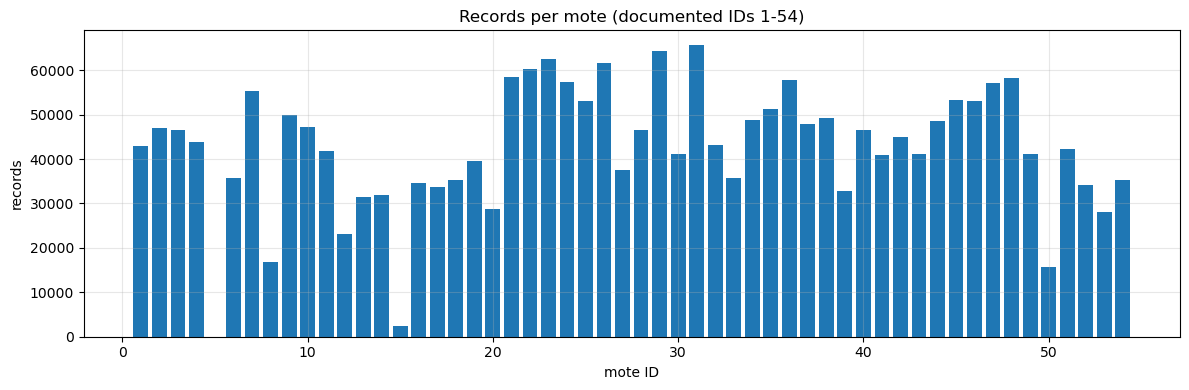

Fewest records:
 moteid
5        35
15     2337
50    15741
8     16778
12    23078
Most records:
 moteid
22    60165
26    61521
23    62440
29    64391
31    65693


In [14]:
per_mote = docu.groupby("moteid").size().reindex(range(1, 55), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(per_mote.index, per_mote.values)
ax.set_xlabel("mote ID"); ax.set_ylabel("records"); ax.set_title("Records per mote (documented IDs 1-54)")
fig.tight_layout(); fig.savefig(FIG / "sensor_coverage.png"); plt.show()
print("Fewest records:\n", per_mote.sort_values().head(5).to_string())
print("Most records:\n", per_mote.sort_values().tail(5).to_string())

### 🔎 Interpretation — Uneven sensor coverage

- Sensor availability is **highly uneven**. Some motes have only a few dozen records while others have more than 60,000.
- This is important: we cannot assume every node has equal data quality or equal usefulness as a peer.
- Later peer selection should therefore consider **data availability** in addition to physical proximity and similarity.
- **Takeaway for the embedded system:** a peer-based decision mechanism needs a way to reject peers that do not have enough recent observations.

## 4. Timestamps and sampling interval
The documentation says "about 31 seconds". We measure it instead of assuming it. The file is not sorted, so we sort by `(moteid, timestamp)` first.

          seconds
count  2303232.00
mean        60.47
std        553.99
min          0.00
1%          14.21
10%         24.41
50%         33.24
90%         96.01
95%        148.98
99%        320.24
max      98324.88


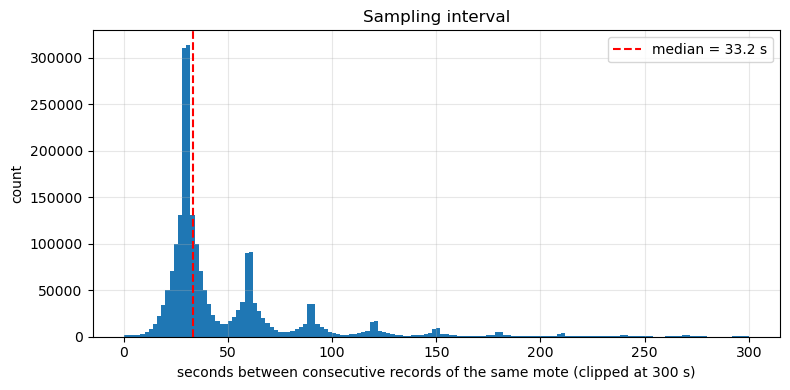

  threshold    gaps
0   > 1 min  587671
1   > 5 min   26091
2  > 30 min    1017
3  > 1 hour     440
4   > 1 day      53


In [17]:
docu = docu.sort_values(["moteid", "timestamp"], kind="stable").reset_index(drop=True)
docu["dt_s"] = docu.groupby("moteid")["timestamp"].diff().dt.total_seconds()

dt = docu["dt_s"].dropna()
interval_stats = dt.describe(percentiles=[.01, .1, .5, .9, .95, .99]).rename("seconds").to_frame()
print(interval_stats.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dt[dt <= 300], bins=150)
ax.axvline(dt.median(), color="red", ls="--", label=f"median = {dt.median():.1f} s")
ax.set_xlabel("seconds between consecutive records of the same mote (clipped at 300 s)")
ax.set_ylabel("count"); ax.set_title("Sampling interval"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "sampling_intervals.png"); plt.show()

gap_table = pd.DataFrame({
    "threshold": ["> 1 min", "> 5 min", "> 30 min", "> 1 hour", "> 1 day"],
    "gaps": [(dt > s).sum() for s in (60, 300, 1800, 3600, 86400)]})
print(gap_table)

### 🔎 Interpretation — Sampling behavior

- The median observed inter-arrival time is **33.24 s**, close to the documented roughly 31-second sensing cadence.
- The mean is much larger (**60.47 s**) because missing transmissions and longer gaps are common.
- There are **587,671 gaps >1 minute**, with progressively fewer gaps lasting >5 minutes, >30 minutes, >1 hour, and >1 day.
- Therefore, the network is **not perfectly periodic** even though its nominal sensing interval is roughly 31 seconds.
- **Takeaway for the embedded system:** windowing and temporal features must tolerate irregular/missing observations rather than assuming perfectly synchronized samples.

## 5. Duplicates

In [20]:
dup_time = int(docu.duplicated(["moteid", "timestamp"]).sum())
dup_epoch = int(docu.duplicated(["moteid", "epoch"]).sum())
print("Duplicate (moteid, timestamp):", dup_time)
print("Repeated   (moteid, epoch)   :", dup_epoch, " <- epoch repeats, so it is NOT a unique key")

Duplicate (moteid, timestamp): 0
Repeated   (moteid, epoch)   : 113601  <- epoch repeats, so it is NOT a unique key


### 🔎 Interpretation — Duplicate checks

- There are **0 duplicate `(moteid, timestamp)` records**, which is good.
- The `epoch` value repeats, so it should **not** be treated as a globally unique identifier.
- The correct time-series identity for this analysis is the combination of **sensor/mote ID + timestamp**.
- **Takeaway:** the dataset has a clean timestamp key for the documented analysis after parsing, while `epoch` should be treated as a measurement field rather than a unique row ID.

## 6. Missing and physically implausible values
Implausible values are only **counted** here (ranges are in `src/intel_utils.py`). They are not removed — they may be real sensor faults, which is exactly what this project studies.

In [23]:
rows = []
for v in u.MEASUREMENTS:
    lo, hi = u.VALID_RANGES[v]
    s = docu[v]
    rows.append({"variable": v, "missing": int(s.isna().sum()),
                 "missing_%": round(100 * s.isna().mean(), 2),
                 "outside_range": int(((s < lo) | (s > hi)).sum()),
                 "outside_range_%": round(100 * ((s < lo) | (s > hi)).mean(), 2),
                 "valid_range": f"{lo} to {hi}",
                 "min": s.min(), "median": s.median(), "max": s.max()})
missingness = pd.DataFrame(rows)
print(missingness.to_string(index=False))

   variable  missing  missing_%  outside_range  outside_range_%   valid_range          min    median      max
temperature      372       0.02         408133            17.72   0.0 to 50.0   -38.400000  22.44820  385.568
   humidity      371       0.02         299084            12.99  0.0 to 100.0 -8983.130000  39.28030  137.512
      light    93205       4.05              0             0.00 0.0 to 2000.0     0.000000 158.24000 1847.360
    voltage        0       0.00           2746             0.12    2.0 to 3.0     0.009101   2.52732   18.560


### 🔎 Interpretation — Missing and physically implausible measurements

The raw data contains substantial values outside the conservative plausibility ranges used for this exploratory quality check:

- Temperature: **408,133 (17.72%)** outside 0–50 °C.
- Humidity: **299,084 (12.99%)** outside 0–100%.
- Light: **4.05% missing**, with no values outside the configured light range.
- Voltage: **0.12%** outside the configured 2–3 V range.

These values should **not automatically be called sensor faults**. At this stage they are best described as **quality/plausibility violations**. Some may represent corruption, sensor failure, or abnormal operating conditions.

**Critical carry-forward rule:** Notebook 2 should preserve the raw measurements and create explicit validity/quality information rather than simply deleting every abnormal value. Those abnormal observations may be useful evidence for the later fault-attribution task.

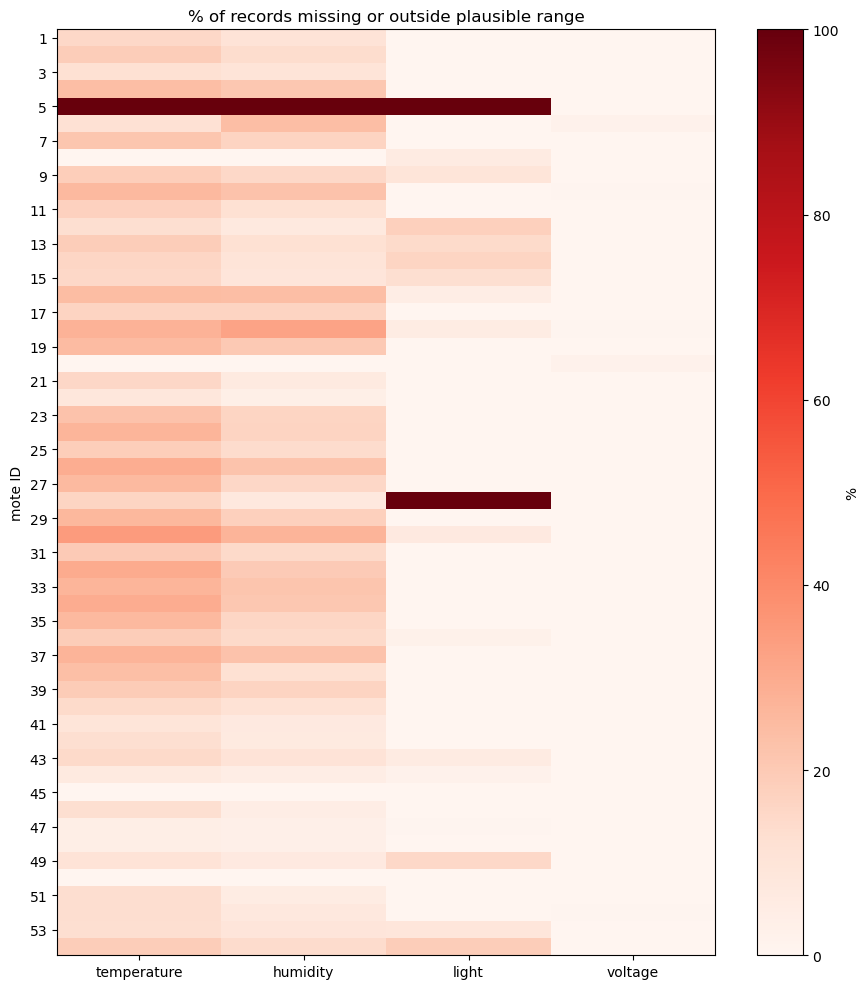

In [25]:
# Share of each mote's records that are missing-or-implausible, per variable
bad = pd.DataFrame({v: ~docu[v].between(*u.VALID_RANGES[v]) for v in u.MEASUREMENTS})  # NaN counts as bad
bad["moteid"] = docu["moteid"]
bad_pct = (100 * bad.groupby("moteid").mean()).reindex(range(1, 55))

fig, ax = plt.subplots(figsize=(9, 10))
im = ax.imshow(bad_pct.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(4)); ax.set_xticklabels(u.MEASUREMENTS)
ax.set_yticks(range(0, 54, 2)); ax.set_yticklabels(range(1, 55, 2))
ax.set_ylabel("mote ID"); ax.set_title("% of records missing or outside plausible range")
ax.grid(False); fig.colorbar(im, label="%"); fig.tight_layout()
fig.savefig(FIG / "missing_invalid_by_mote.png"); plt.show()

### When do the sensors go bad?
Valid temperature share per day, and how many motes still report plausible temperatures. This decides which dates are usable.

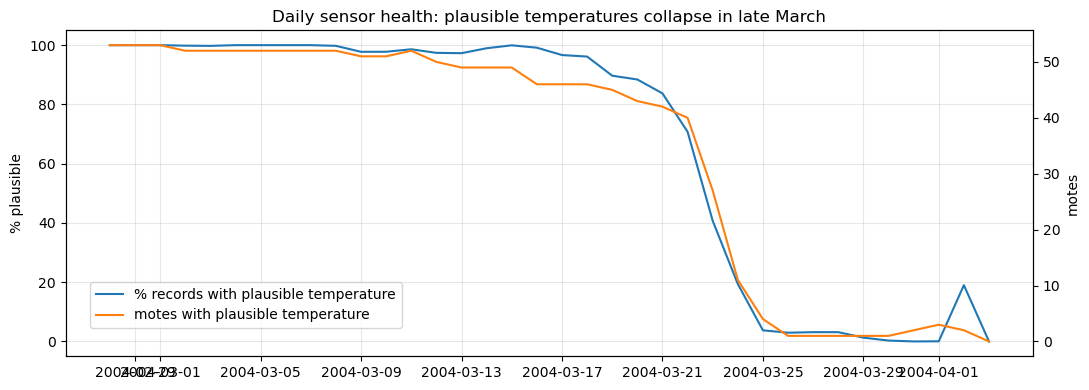

            valid_temperature_share  motes_with_valid_temperature
timestamp                                                        
2004-02-28                     1.00                          53.0
2004-02-29                     1.00                          53.0
2004-03-01                     1.00                          53.0
2004-03-02                     1.00                          52.0
2004-03-03                     1.00                          52.0
2004-03-04                     1.00                          52.0
2004-03-05                     1.00                          52.0
2004-03-06                     1.00                          52.0
2004-03-07                     1.00                          52.0
2004-03-08                     1.00                          52.0
2004-03-09                     0.98                          51.0
2004-03-10                     0.98                          51.0
2004-03-11                     0.99                          52.0
2004-03-12

In [27]:
day = docu["timestamp"].dt.floor("D")
ok_t_mask = docu["temperature"].between(*u.VALID_RANGES["temperature"])
daily = pd.DataFrame({"valid_temperature_share": ok_t_mask.groupby(day).mean(),
                      "motes_with_valid_temperature": docu[ok_t_mask].groupby(day)["moteid"].nunique()}).fillna(0)
fig, ax = plt.subplots(figsize=(11, 4)); ax2 = ax.twinx()
ax.plot(daily.index, 100 * daily["valid_temperature_share"], color="tab:blue", label="% records with plausible temperature")
ax2.plot(daily.index, daily["motes_with_valid_temperature"], color="tab:orange", label="motes with plausible temperature")
ax.set_ylabel("% plausible"); ax2.set_ylabel("motes"); ax2.grid(False)
ax.set_title("Daily sensor health: plausible temperatures collapse in late March")
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.15)); fig.tight_layout()
fig.savefig(FIG / "daily_valid_temperature.png"); plt.show()
print(daily.round(2).to_string())


### 🔎 Interpretation — Temporal degradation of measurement validity

- Valid temperature coverage is initially very high, but it deteriorates substantially later in the deployment.
- The number of motes with valid temperature readings also decreases over time.
- The late-March collapse is a **network/sensor-health observation**, not by itself proof of a particular fault mechanism.
- We should not label this phenomenon as “sensor drift” without additional evidence.
- **Takeaway:** the system needs to distinguish genuine environmental changes from sensor/network degradation and missing/invalid measurements.

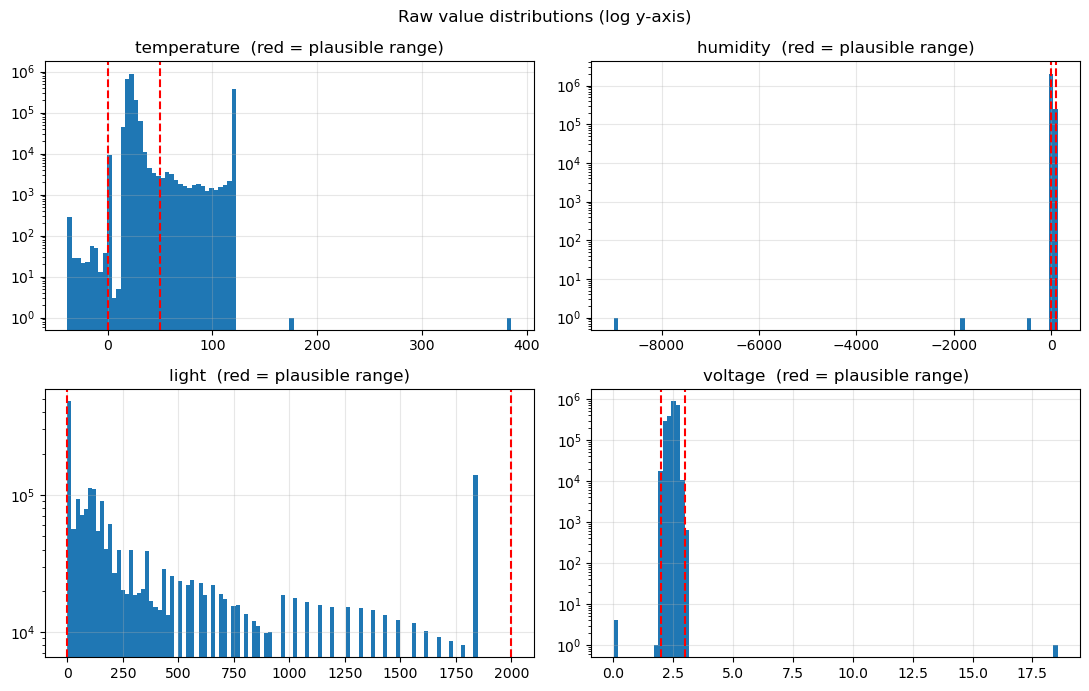

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, v in zip(axes.ravel(), u.MEASUREMENTS):
    ax.hist(docu[v].dropna(), bins=100)
    lo, hi = u.VALID_RANGES[v]
    ax.axvline(lo, color="red", ls="--"); ax.axvline(hi, color="red", ls="--")
    ax.set_yscale("log"); ax.set_title(f"{v}  (red = plausible range)")
fig.suptitle("Raw value distributions (log y-axis)"); fig.tight_layout()
fig.savefig(FIG / "measurement_distributions.png"); plt.show()

### 🔎 Interpretation — Measurement-quality trend plots

The plots provide a visual confirmation of the earlier statistics: measurement validity is relatively strong earlier in the deployment and degrades substantially toward the later period.

The important research implication is that **data quality itself changes over time**. This is relevant to an embedded monitoring system because an edge node cannot assume that a sensor that was reliable earlier will remain reliable indefinitely.

## 7. Representative time series
Selection rule (reproducible): the 3 documented motes with the most records.

Representative motes: [31, 29, 23]


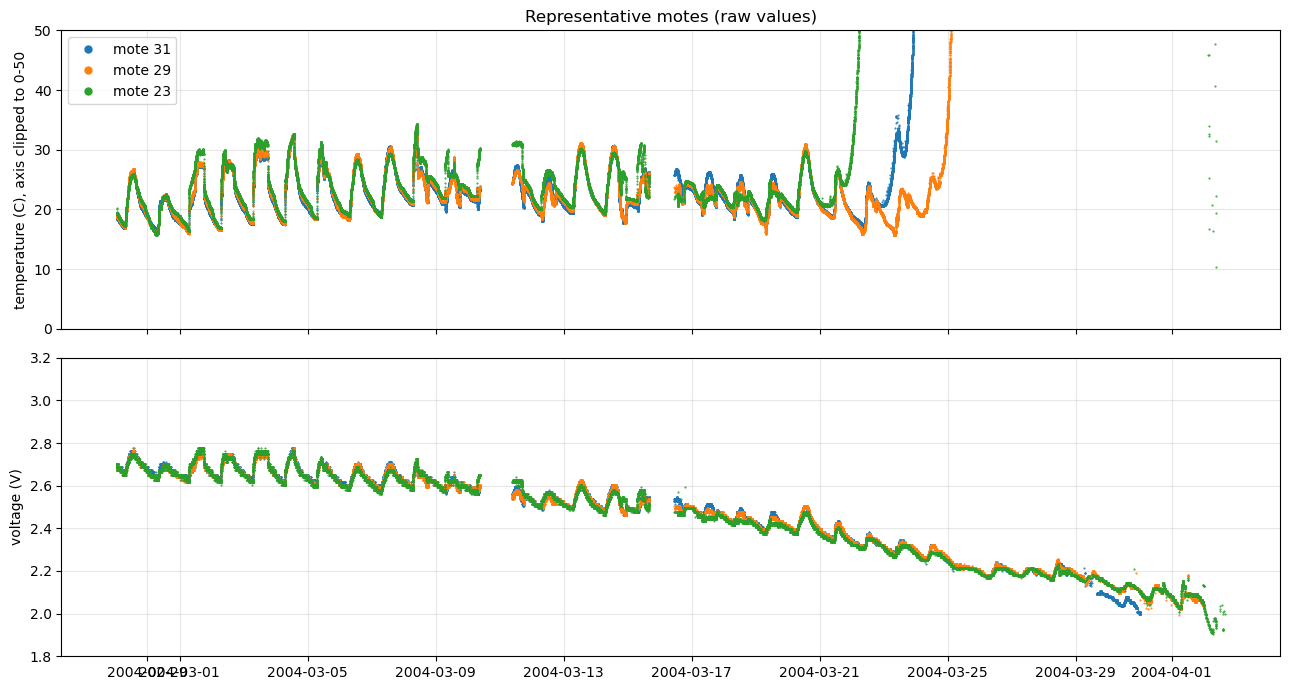

In [32]:
rep = per_mote.sort_values(ascending=False).head(3).index.tolist()
print("Representative motes:", rep)
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for m in rep:
    d = docu[docu["moteid"] == m]
    axes[0].plot(d["timestamp"], d["temperature"], ".", ms=1, label=f"mote {m}")
    axes[1].plot(d["timestamp"], d["voltage"], ".", ms=1, label=f"mote {m}")
axes[0].set_ylim(0, 50); axes[0].set_ylabel("temperature (C), axis clipped to 0-50")
axes[1].set_ylim(1.8, 3.2); axes[1].set_ylabel("voltage (V)")
axes[0].legend(markerscale=10); axes[0].set_title("Representative motes (raw values)")
fig.tight_layout(); fig.savefig(FIG / "representative_sensor_timeseries.png"); plt.show()

### 🔎 Interpretation — Representative sensor time series

- Motes **31, 29, and 23** were selected reproducibly because they have the highest record counts among the documented motes.
- Their time series show shared temporal structure while retaining sensor-specific variation.
- This is promising for peer-based reasoning: if several nearby/related sensors move together while one sensor diverges, that divergence can potentially provide evidence for a sensor-specific problem.
- These three motes are useful for exploration, but they should **not automatically become the permanent peer set**. Later notebooks should use a principled peer-selection strategy.

## 8. Do neighbouring sensors agree? (cross-sensor correlation)
Peer-based drift detection only works if sensors share the same environment. We bin *plausible* temperatures into 5-minute averages and correlate motes.

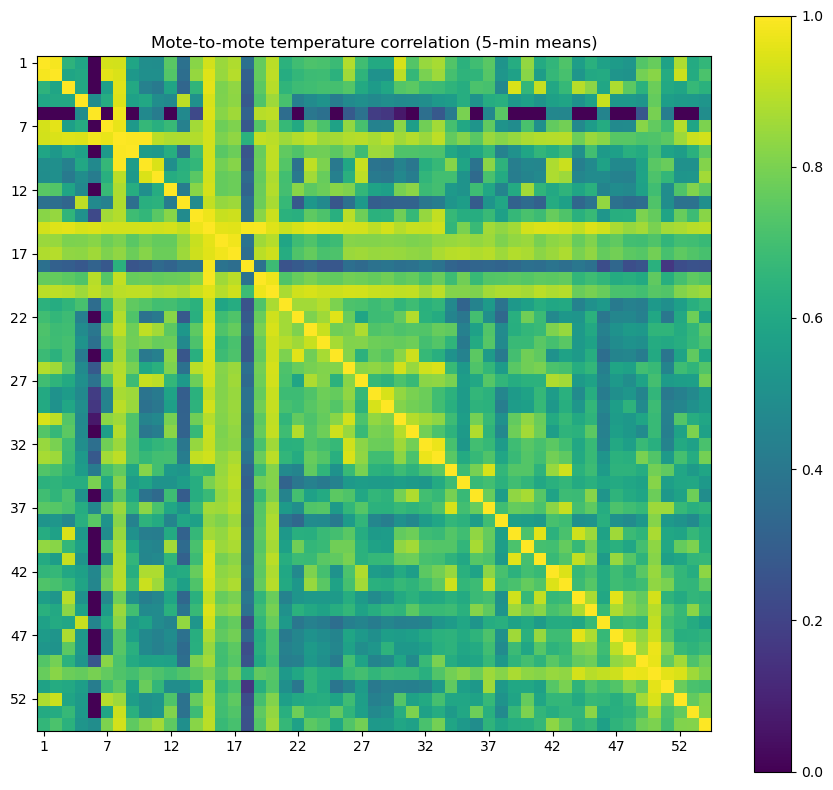

Median pairwise correlation: 0.674


In [35]:
ok_t = docu[docu["temperature"].between(*u.VALID_RANGES["temperature"])]
piv = (ok_t.assign(bin=ok_t["timestamp"].dt.floor("5min"))
            .groupby(["bin", "moteid"])["temperature"].mean().unstack("moteid"))
corr = piv.corr(min_periods=500)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(0, len(corr), 5)); ax.set_xticklabels(corr.columns[::5])
ax.set_yticks(range(0, len(corr), 5)); ax.set_yticklabels(corr.index[::5])
ax.grid(False); ax.set_title("Mote-to-mote temperature correlation (5-min means)")
fig.colorbar(im); fig.tight_layout(); fig.savefig(FIG / "sensor_correlation_matrix.png"); plt.show()
off_diag = corr.values[~np.eye(len(corr), dtype=bool)]
print(f"Median pairwise correlation: {np.nanmedian(off_diag):.3f}")

### 🔎 Interpretation — Cross-sensor correlation

- The median pairwise temperature correlation is **0.674**.
- This indicates meaningful shared behavior across sensors, while correlations are clearly not perfect.
- That combination is useful for this project: there is enough redundancy to support peer comparison, but enough variation that peer agreement cannot be assumed.
- **Important:** this exploratory all-pair correlation should not be interpreted as the final peer topology. Later peer selection should incorporate physical proximity, data availability, and potentially recent similarity.
- **Takeaway:** peer-based fault attribution is empirically plausible for this dataset and worth carrying into the next stages.

## 9. Per-mote table and saved outputs

In [38]:
g = docu.groupby("moteid")
sensor_stats = pd.DataFrame({
    "records": g.size(),
    "first_timestamp": g["timestamp"].min(),
    "last_timestamp": g["timestamp"].max(),
    "median_interval_s": g["dt_s"].median(),
    "p95_interval_s": g["dt_s"].quantile(0.95),
    "max_gap_s": g["dt_s"].max(),
}).reindex(range(1, 55))
sensor_stats["records"] = sensor_stats["records"].fillna(0).astype(int)
for v in u.MEASUREMENTS:
    sensor_stats[f"{v}_bad_%"] = bad_pct[v].round(2)
sensor_stats.index.name = "moteid"

dataset_summary = pd.DataFrame({"item": [
    "raw_lines", "documented_mote_records", "motes_present_of_54", "first_timestamp", "last_timestamp",
    "unparseable_timestamps", "duplicate_moteid_timestamp", "median_interval_s", "raw_sha256"],
  "value": [len(raw), len(docu), docu["moteid"].nunique(), docu["timestamp"].min(), docu["timestamp"].max(),
            int(raw["timestamp"].isna().sum()), dup_time, round(float(dt.median()), 2), RAW_HASH_BEFORE]})

dataset_summary.to_csv(OUT / "dataset_summary.csv", index=False)
rt_counts.to_csv(OUT / "record_type_counts.csv")
sensor_stats.to_csv(OUT / "sensor_statistics.csv")
interval_stats.to_csv(OUT / "sampling_interval_statistics.csv")
missingness.to_csv(OUT / "missingness_summary.csv", index=False)
dataset_summary

,item,value
0,raw_lines,2313682
1,documented_mote_records,2303286
2,motes_present_of_54,54
3,first_timestamp,2004-02-28 00:58:46.002832
4,last_timestamp,2004-04-03 16:51:34.171452
5,unparseable_timestamps,4
6,duplicate_moteid_timestamp,0
7,median_interval_s,33.24
8,raw_sha256,21d156880db48eb140390beffc18b017282777cdc41e30...


### 🔎 Interpretation — Saved dataset summary

The summary table records the key provenance and integrity facts needed by later notebooks:

- 2,313,682 raw lines
- 2,303,286 documented, timestamp-valid records used for primary analysis
- 54 documented motes present
- 4 unparseable timestamps
- 0 duplicate `(moteid, timestamp)` records
- 33.24 s median observed interval

The raw-file SHA-256 is also stored, which helps prove that the source data was not modified during the pipeline.

**Takeaway:** Notebook 2 can now build on a reproducibly defined primary dataset without losing traceability to the original raw file.

## 10. Validation checks

In [41]:
# 1. raw file untouched
assert sha256(RAW_FILE) == RAW_HASH_BEFORE, "Raw file changed!"
# 2. every line accounted for
assert rt_counts["records"].sum() == n_lines_in_file
# 3. every documented mote appears at least once... (report, not fail: some may be truly absent)
absent = [m for m in range(1, 55) if per_mote[m] == 0]
print("Documented motes with zero records:", absent)
# 4. no duplicate (moteid, timestamp) -- this is what NB2 relies on
assert dup_time == 0, f"{dup_time} duplicate (moteid, timestamp) rows: handle them in Notebook 2"
# 5. sorted within mote
assert docu.groupby("moteid")["timestamp"].apply(lambda s: s.is_monotonic_increasing).all()
# 6. all expected output files exist and are non-empty
for name in ["dataset_summary.csv", "record_type_counts.csv", "sensor_statistics.csv",
             "sampling_interval_statistics.csv", "missingness_summary.csv"]:
    assert (OUT / name).stat().st_size > 0, name
for name in ["sensor_coverage.png", "sampling_intervals.png", "missing_invalid_by_mote.png",
             "measurement_distributions.png", "representative_sensor_timeseries.png",
             "sensor_correlation_matrix.png", "daily_valid_temperature.png"]:
    assert (FIG / name).stat().st_size > 0, name
print("ALL NOTEBOOK 1 CHECKS PASSED")

Documented motes with zero records: []
ALL NOTEBOOK 1 CHECKS PASSED


### ✅ Final validation — Notebook 1

**ALL NOTEBOOK 1 CHECKS PASSED.**

The automated checks confirm that the notebook's core assumptions and integrity checks passed for this run.

This means Notebook 1 is **operationally successful**. The remaining considerations are methodological/documentation choices—not evidence that the execution failed.

**Decision:** Notebook 1 can be carried forward as the baseline dataset-audit stage. Before Notebook 2, preserve the distinction between:

1. raw observations,
2. quality/plausibility violations,
3. missing/incomplete observations, and
4. confirmed fault labels (which have not yet been established).

## What we learned (carry into Notebook 2)
- Records have to be sorted by `(moteid, timestamp)` — the file order is not chronological.
- Sampling is irregular (see interval table), not a fixed 31 s.
- IDs outside 1–54 exist and are set aside; they are counted, not hidden.
- About 18% of temperature and 13% of humidity values are physically implausible. They are concentrated in late March (daily plot): from ~2004-03-22 the sensors fail network-wide, so Notebook 2 stops the dataset at that date. Implausible values are **flagged**, not deleted.
- `epoch` repeats within a mote, so it is not used as a key.
- Mote locations are not in the supplied file, so peers cannot yet be chosen by distance (needed in Notebook 3/4).

## Research handoff to Notebook 2

### What Notebook 1 establishes

1. The raw dataset loads completely: **2,313,682 lines → 2,313,682 loaded records**.
2. The primary documented network contains **54 motes (IDs 1–54)**.
3. The observed sampling process is irregular despite a nominal cadence of roughly 31 seconds.
4. Missing/incomplete transmissions are common enough to matter for an edge pipeline.
5. Sensor coverage is highly uneven across motes.
6. A substantial number of raw measurements violate the exploratory plausibility ranges.
7. Cross-sensor temperature correlation is meaningful (**median pairwise correlation = 0.674**), supporting further peer-based analysis.
8. Measurement validity deteriorates strongly later in the deployment.

### What Notebook 1 does **not** establish

- An implausible value is **not automatically a confirmed sensor fault**.
- The late-deployment degradation is **not automatically proven to be sensor drift**.
- The three representative motes are **not the final peer topology**.
- Correlation alone is **not sufficient to establish causality**.

### Design implication

The next stage should build an **edge-oriented preprocessing pipeline** that preserves raw provenance, explicitly flags invalid/missing observations, handles irregular timing, and avoids deleting potentially informative fault behavior before the later fault-attribution stages.